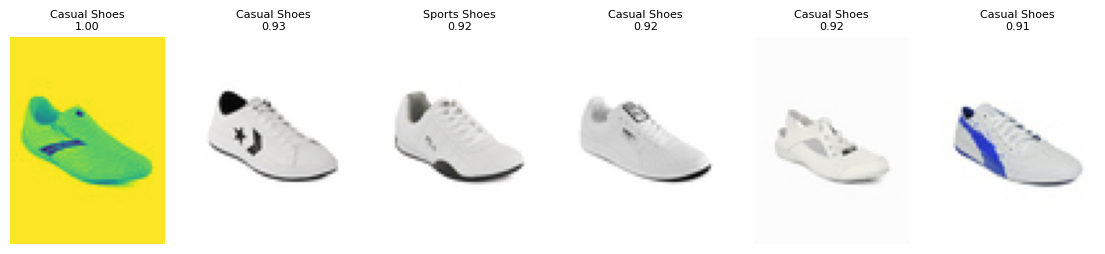

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

P = Path("..") / "data" / "processed"
z = np.load(P / "embeddings.npz")
X = z["X"]
products = pd.read_csv(P / "products.csv")

Xn = X / np.linalg.norm(X, axis=1, keepdims=True)
q = 123
sims = Xn @ Xn[q]
nn = np.argsort(-sims)[:6]          # first one is the query itself

fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for ax, i in zip(axes, nn):
    ax.imshow(Image.open(Path("..") / products.image_path[i]))
    ax.set_title(f"{products.articleType[i]}\n{sims[i]:.2f}", fontsize=8)
    ax.axis("off")
plt.show()

In [2]:
import pandas as pd
p = pd.read_csv("../data/processed/products.csv")
c = pd.read_csv("../data/processed/clusters.csv")
m = p.merge(c[["id", "cluster"]], on="id")
s = m[m.articleType == "Shirts"]
print(pd.crosstab(s.cluster, s.gender))
print(pd.crosstab(s.cluster, s.usage))

gender   Boys  Men  Women
cluster                  
0           0  134     18
1           0  282     22
2           0   20      0
3          15    9      0
usage    Casual  Ethnic  Formal  Smart Casual
cluster                                      
0           150       0       2             0
1           170       1     131             2
2             5       0      15             0
3            24       0       0             0
